# 01 · Data Cleaning & Exploratory Data Analysis (EDA)

**Project:** E-Commerce Customer Segmentation & Retention (Python + SQL + ML)
**Author:** Priyanshu · Aspiring Data Analyst

### What this notebook does
1. Loads the raw *Online Retail II* data (UK online gift retailer, Dec 2009 – Dec 2011, ~1.07 million rows)
2. **Audits** the data quality (what is broken and how badly?)
3. **Cleans** it step by step, logging how many rows each step removes (so every decision can be defended)
4. Explores it with charts to understand the business **before** modelling
5. Saves clean files that the SQL and ML parts of the project use

### My approach (how I work)
For every step I write: **What** I am doing → **Why** → the code (commented line by line) → **Evaluation** (did it work? what are the risks?).

## Step 0 · Setup
**What:** import libraries and set paths. **Why:** keep all settings in one place so the notebook is easy to re-run.

In [2]:
# ---- import the libraries I will use ----
import pandas as pd                 # tables (DataFrames) -> my main tool for data work
import numpy as np                  # maths helpers (log, percentiles, etc.)
import matplotlib.pyplot as plt     # base plotting library
import seaborn as sns               # nicer statistical charts built on matplotlib
from pathlib import Path            # builds file paths that work on Windows, Mac and Linux

# ---- consistent chart style for the whole project ----
sns.set_theme(style="whitegrid", palette="deep")          # clean white grid look
plt.rcParams["figure.figsize"] = (10, 5)                  # default chart size (width, height)
pd.options.display.float_format = "{:,.2f}".format        # show numbers like 1,234.56 instead of 1234.5600001

# ---- folder paths (relative to the notebooks/ folder) ----
ROOT = Path("..")                                         # project root is one level above notebooks/
RAW_FILE = ROOT / "data" / "raw" / "online_retail_II.csv.gz"   # original data, exactly as downloaded
PROCESSED = ROOT / "data" / "processed"                   # cleaned data goes here
IMAGES = ROOT / "images"                                  # charts for the README go here
PROCESSED.mkdir(parents=True, exist_ok=True)              # create the folder if it does not exist yet
IMAGES.mkdir(parents=True, exist_ok=True)

## Step 1 · Load the raw data
**What:** read the CSV into a DataFrame. **Why:** everything else starts here.

Two small choices I made:
- `parse_dates` turns the text in `InvoiceDate` into real datetimes so I can do date maths later.
- `dtype=str` for `Invoice` and `StockCode` because they are **IDs, not numbers** (some contain letters, e.g. `C489449` or `85123A`). If pandas guessed numeric, it could silently break them.

In [3]:
# read the compressed CSV directly (pandas can read .gz files without unzipping)
raw = pd.read_csv(
    RAW_FILE,
    parse_dates=["InvoiceDate"],                      # convert text -> datetime
    dtype={"Invoice": "str", "StockCode": "str"},     # keep IDs as text
)

# "Customer ID" has a space in it. Spaces in column names cause backtick problems in MySQL,
# so I rename it right now to avoid trouble later.
raw = raw.rename(columns={"Customer ID": "CustomerID"})

print("Shape (rows, columns):", raw.shape)            # how big is the data?
raw.head()                                            # first 5 rows to see what the data looks like

Shape (rows, columns): (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
# .info() shows column names, data types and non-null counts in one view
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   CustomerID   824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 65.1 MB


**Evaluation:** ~1.07 M rows × 8 columns. `CustomerID` and `Description` already show missing values (non-null count is lower than the row count). `CustomerID` is stored as a decimal (float) only because pandas needs floats to hold missing values — I will convert it to an integer once the missing rows are gone.

### Data dictionary (what each column means)
| Column | Meaning |
|---|---|
| Invoice | Order number. **If it starts with `C` it is a cancellation / return** |
| StockCode | Product code |
| Description | Product name |
| Quantity | Units in that line (negative for returns) |
| InvoiceDate | Date and time of the order |
| Price | Unit price in £ |
| CustomerID | Customer identifier (missing for some orders) |
| Country | Customer's country |

## Step 2 · Data quality audit
**What:** measure every problem *before* fixing anything. **Why:** if I fix blindly I cannot explain what I changed or how much it matters. Each check below is something I noticed in `.info()` or the business context.

In [4]:
# --- Check 1: missing values per column (as a % so I can compare columns) ---
missing = raw.isna().sum()                                  # count of NaN per column
missing_pct = (missing / len(raw) * 100).round(2)           # convert to percentage of all rows
pd.DataFrame({"missing_rows": missing, "missing_%": missing_pct})

,missing_rows,missing_%
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
CustomerID,243007,22.77
Country,0,0.00


In [5]:
# --- Check 2: exact duplicate rows ---
# .duplicated() marks every row that is identical to an EARLIER row (all 8 columns the same)
n_dup = raw.duplicated().sum()
print(f"Duplicate rows: {n_dup:,}  ({n_dup/len(raw):.2%} of all rows)")

# --- Check 3: cancellations (Invoice starts with 'C') ---
is_cancel = raw["Invoice"].str.startswith("C")              # True for return/cancel invoices
print(f"Cancellation rows: {is_cancel.sum():,}  ({is_cancel.mean():.2%})")

# --- Check 4: strange quantities / prices ---
print(f"Rows with Quantity <= 0: {(raw['Quantity'] <= 0).sum():,}")
print(f"Rows with Price <= 0   : {(raw['Price'] <= 0).sum():,}")

# --- Check 5: stock codes that are NOT real products ---
# real products start with 5 digits (e.g. 85123A). Let me list codes that do not.
odd_codes = raw.loc[~raw["StockCode"].str.match(r"^\d{5}"), ["StockCode", "Description"]]
odd_summary = (odd_codes.groupby("StockCode")["Description"]
               .agg(rows="size", example="first")           # how many rows + one example description
               .sort_values("rows", ascending=False))
odd_summary.head(12)

Duplicate rows: 34,335  (3.22% of all rows)
Cancellation rows: 19,494  (1.83%)
Rows with Quantity <= 0: 22,950
Rows with Price <= 0   : 6,207


,rows,example
StockCode,,
POST,2122,POSTAGE
DOT,1446,DOTCOM POSTAGE
M,1421,Manual
C2,282,CARRIAGE
D,177,Discount
S,104,SAMPLES
BANK CHARGES,102,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,AMAZON FEE


**Evaluation of the audit**
- **~22.8% of rows have no CustomerID.** Segmentation and retention are about *customers*, so rows without an ID cannot be used — but I must remember this when reporting totals (they are not "all sales").
- **~3% exact duplicates** — most likely data-entry / export repeats.
- **~1.8% cancellation rows** — these are returns, not sales. Mixing them with sales would make revenue wrong. I will keep them in a **separate table** because return behaviour is useful for churn later.
- **Non-product codes** like `POST` (postage), `BANK CHARGES`, `AMAZONFEE`, `ADJUST`, `TEST001`, `gift_...` vouchers, and `D` (discount) are *services/fees*, not products. They would distort "top products" and average order value.

**Risk I noted:** dropping duplicates assumes they are errors. A customer could in theory scan the same item twice on the same invoice. Because duplicates are only ~3% the effect is small, but I will mention it as a limitation.

## Step 3 · Cleaning pipeline (with a log)
**What:** apply cleaning rules one at a time and record the row count after each rule.
**Why (optimization):** a log makes the cleaning *transparent and reproducible* — an interviewer can see exactly what each rule costs.

In [6]:
# a tiny list that will store (step name, rows remaining) after each cleaning rule
cleaning_log = []

def log_step(step_name, data):
    # helper: remember how many rows are left after this step and print it
    cleaning_log.append({"step": step_name, "rows_remaining": len(data)})
    print(f"{step_name:<45} rows left: {len(data):>9,}")

df = raw.copy()                         # work on a COPY so the raw data stays untouched in memory
log_step("0. raw data", df)

# ---- Rule 1: remove exact duplicate rows ----
df = df.drop_duplicates()               # keeps the first copy, drops later identical copies
log_step("1. drop exact duplicates", df)

# ---- Rule 2: remove rows with no CustomerID ----
# subset=[...] means: only look at this column when deciding what to drop
df = df.dropna(subset=["CustomerID"])
log_step("2. drop rows with no CustomerID", df)

# ---- Rule 3: split cancellations away from sales ----
is_cancel = df["Invoice"].str.startswith("C")       # True where invoice starts with C
returns = df[is_cancel].copy()                      # keep cancellations in their own table
df = df[~is_cancel]                                 # ~ means NOT -> keep only normal sales
log_step("3. move cancellation invoices to 'returns'", df)

# ---- Rule 4: remove non-product stock codes (postage, fees, tests, vouchers...) ----
# regex explanation: ^( ... )$ = the WHOLE code must equal one of these patterns
#   ADJUST\d* = ADJUST, ADJUST2 | TEST\d+ = TEST001 | gift_.* = any gift voucher code
non_product_pattern = r"^(POST|DOT|M|C2|C3|D|S|B|BANK CHARGES|ADJUST\d*|AMAZONFEE|CRUK|TEST\d+|PADS|gift_.*)$"
is_non_product = df["StockCode"].str.match(non_product_pattern, case=False)   # case=False so 'm' = 'M'
df = df[~is_non_product]
log_step("4. drop non-product stock codes", df)

# ---- Rule 5: remove any leftover rows with Quantity <= 0 or Price <= 0 ----
# (e.g. 'damaged', 'check' stock adjustments with price 0 - not real customer purchases)
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
log_step("5. drop Quantity<=0 or Price<=0", df)

0. raw data                                   rows left: 1,067,371


1. drop exact duplicates                      rows left: 1,033,036
2. drop rows with no CustomerID               rows left:   797,885


3. move cancellation invoices to 'returns'    rows left:   779,495


4. drop non-product stock codes               rows left:   776,639
5. drop Quantity<=0 or Price<=0               rows left:   776,579


In [7]:
# ---- Rule 6: create new columns I will need later ----
# .round(2) = pennies only. Without it, a cancelled order can leave a tiny float residue like 0.0000000001
# instead of exactly 0, which flipped some customers between "net > 0" and "net <= 0" in my first run.
df["Revenue"] = (df["Quantity"] * df["Price"]).round(2)         # money earned on each line
df["CustomerID"] = df["CustomerID"].astype(int)                 # float -> int (no missing values left, so safe)
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)   # e.g. '2011-03' for monthly trends
df["InvoiceDay"] = df["InvoiceDate"].dt.date                    # date only (no time) -> used for cohorts / recency

# same treatment for the returns table so both tables match
returns["Revenue"] = (returns["Quantity"] * returns["Price"]).round(2)   # negative numbers (money going back)
returns["CustomerID"] = returns["CustomerID"].astype(int)
returns = returns[~returns["StockCode"].str.match(non_product_pattern, case=False)]  # same non-product filter
log_step("6. final clean sales table", df)
print("Returns table rows:", len(returns))

6. final clean sales table                    rows left:   776,579
Returns table rows: 17586


In [8]:
# ---- Evaluation: automatic checks. If any assert fails, Python stops and tells me something is wrong ----
assert df["CustomerID"].notna().all(),           "there are still missing customer IDs"
assert not df.duplicated().any(),                "there are still duplicate rows"
assert (df["Quantity"] > 0).all(),               "non-positive quantity left"
assert (df["Price"] > 0).all(),                  "non-positive price left"
assert (df["Revenue"] > 0).all(),                "non-positive revenue left"
assert not df["Invoice"].str.startswith("C").any(), "a cancellation slipped into sales"
print("All data-quality checks passed")

# visualise how many rows each step removed
log_df = pd.DataFrame(cleaning_log)
log_df["rows_removed"] = (-log_df["rows_remaining"].diff()).fillna(0).astype(int)   # difference vs previous step
log_df["pct_of_raw_kept"] = (log_df["rows_remaining"] / log_df["rows_remaining"].iloc[0] * 100).round(1)
log_df

All data-quality checks passed


,step,rows_remaining,rows_removed,pct_of_raw_kept
0,0. raw data,1067371,0,100.00
1,1. drop exact duplicates,1033036,34335,96.80
2,2. drop rows with no CustomerID,797885,235151,74.80
3,3. move cancellation invoices to 'returns',779495,18390,73.00
4,4. drop non-product stock codes,776639,2856,72.80
5,5. drop Quantity<=0 or Price<=0,776579,60,72.80
6,6. final clean sales table,776579,0,72.80


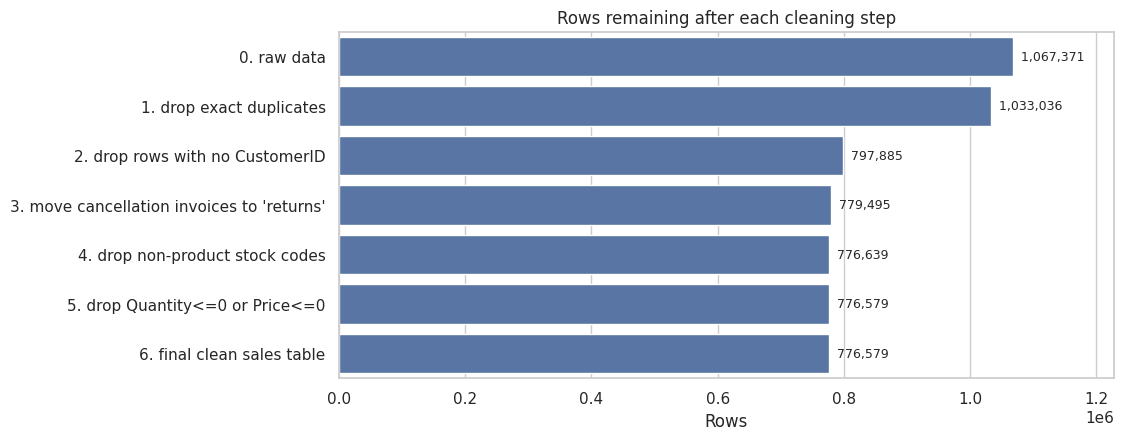

In [9]:
# bar chart of rows remaining after every step (a simple 'funnel' view)
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=log_df, y="step", x="rows_remaining", color="#4C72B0", ax=ax)   # horizontal bars
ax.set_title("Rows remaining after each cleaning step")
ax.set_xlabel("Rows")
ax.set_ylabel("")
for i, v in enumerate(log_df["rows_remaining"]):          # write the exact number at the end of each bar
    ax.text(v, i, f"  {v:,}", va="center", fontsize=9)
ax.set_xlim(0, log_df["rows_remaining"].max() * 1.15)     # leave room for the labels
plt.savefig(IMAGES / "01_cleaning_funnel.png", dpi=150, bbox_inches="tight")   # save for README
plt.show()

**Evaluation of cleaning**
- I kept **~73% of the raw rows**. The biggest loss (~22%) is rows with no CustomerID — unavoidable because I need customers for this project.
- Duplicates, non-product codes and bad price/quantity rows together removed < 5%, so these decisions do not change the picture much.
- All `assert` checks passed, so the clean table is internally consistent.
- **Limitation:** revenue from customers with no ID (the 22.8%) is excluded, so all totals in this project mean *"revenue from identified customers"*.

## Step 4 · Outlier check (a thing I almost missed)
**What:** look at the largest orders. **Why:** a few giant orders can completely distort averages and later customer segments.

In [10]:
# top 5 individual lines by revenue
top_lines = df.nlargest(5, "Revenue")[["Invoice", "CustomerID", "StockCode", "Description", "Quantity", "Price", "Revenue", "InvoiceDate"]]
top_lines

,Invoice,CustomerID,StockCode,Description,Quantity,Price,Revenue,InvoiceDate
1065882,581483,16446,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60",2011-12-09 09:15:00
587080,541431,12346,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60",2011-01-18 10:01:00
748132,556444,15098,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",2011-06-10 15:28:00
432176,530715,15838,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,"15,818.40",2010-11-04 11:36:00
228042,511465,18008,15044A,PINK PAPER PARASOL,3500,2.55,"8,925.00",2010-06-08 12:59:00


In [11]:
# For each giant line, search the RETURNS table for the same customer + same product + same quantity (negative).
# If I find one, that big order was cancelled afterwards, so it was never real revenue.
for _, row in top_lines.iterrows():
    match = returns[
        (returns["CustomerID"] == row["CustomerID"]) &            # same customer
        (returns["StockCode"] == row["StockCode"]) &              # same product
        (returns["Quantity"] == -row["Quantity"])                 # exactly opposite quantity
    ]
    print(f"Invoice {row['Invoice']} | customer {row['CustomerID']} | revenue £{row['Revenue']:>10,.2f} "
          f"| matching cancellation found: {len(match) > 0}")

Invoice 581483 | customer 16446 | revenue £168,469.60 | matching cancellation found: True
Invoice 541431 | customer 12346 | revenue £ 77,183.60 | matching cancellation found: True
Invoice 556444 | customer 15098 | revenue £ 38,970.00 | matching cancellation found: True
Invoice 530715 | customer 15838 | revenue £ 15,818.40 | matching cancellation found: True
Invoice 511465 | customer 18008 | revenue £  8,925.00 | matching cancellation found: False


**Evaluation (important finding):** **4 of the 5 biggest lines were later cancelled** by the same customer with exactly the opposite quantity (including the £168k and £77k orders). If I only used the sales table, those customers would look like my best customers in the whole business — which is wrong.

**Optimization decision:** from here on I measure money as **net revenue = sales + returns** (returns are stored as negative numbers). Fully-cancelled orders then cancel themselves out. I do *not* delete the sales rows; the returns table keeps the story complete. I will apply the same rule in the SQL RFM step.

## Step 5 · Exploratory Data Analysis (EDA)
**What:** understand the business through charts and numbers. **Why:** good segmentation needs me to know what "normal" looks like first.

### 5.1 Key numbers (KPIs)

In [12]:
# ---- headline KPIs from the clean sales table ----
total_revenue = df["Revenue"].sum()                         # sum of all line revenues
n_orders = df["Invoice"].nunique()                          # unique invoices = number of orders
n_customers = df["CustomerID"].nunique()                    # unique customers
aov = total_revenue / n_orders                              # Average Order Value = revenue / orders
items_per_order = df.groupby("Invoice")["Quantity"].sum().mean()   # average units in one order

returns_value = -returns["Revenue"].sum()                   # returns are negative, so flip the sign
net_revenue = total_revenue - returns_value                 # what the business really kept
print(f"Gross sales (identified customers)  : £{total_revenue:,.0f}")
print(f"Returned / cancelled value          : £{returns_value:,.0f}  ({returns_value/total_revenue:.1%} of gross)")
print(f"NET revenue (gross - returns)       : £{net_revenue:,.0f}")
print(f"Number of orders                    : {n_orders:,}")
print(f"Number of customers                 : {n_customers:,}")
print(f"Average order value (AOV)           : £{aov:,.2f}")
print(f"Average units per order             : {items_per_order:,.1f}")
print(f"Date range                          : {df['InvoiceDate'].min().date()} to {df['InvoiceDate'].max().date()}")

Gross sales (identified customers)  : £17,068,583
Returned / cancelled value          : £709,953  (4.2% of gross)
NET revenue (gross - returns)       : £16,358,629
Number of orders                    : 36,594
Number of customers                 : 5,852
Average order value (AOV)           : £466.43
Average units per order             : 286.9
Date range                          : 2009-12-01 to 2011-12-09


### 5.2 Revenue trend over time

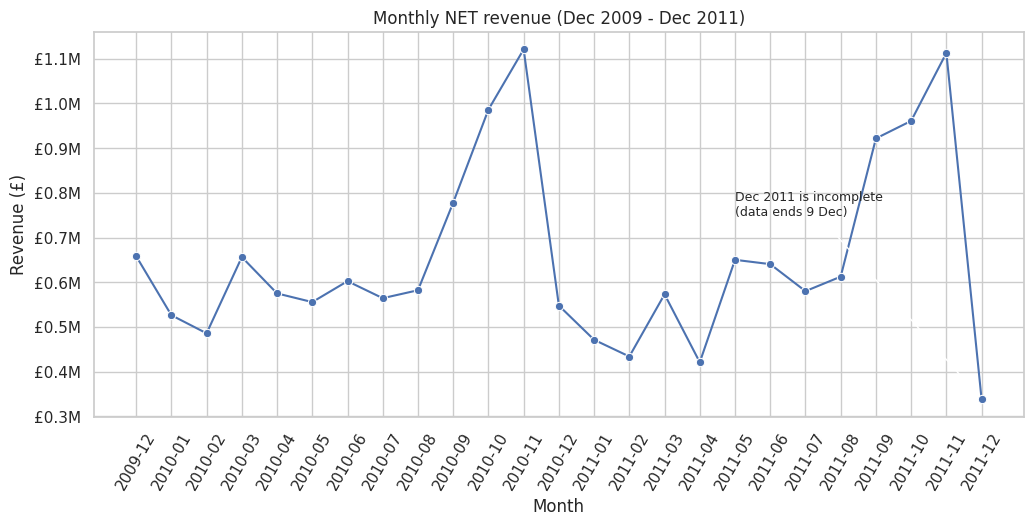

InvoiceMonth
2010-09     778,185.00
2010-10     986,339.00
2010-11   1,121,081.00
2011-09     921,809.00
2011-10     961,042.00
2011-11   1,113,102.00
Name: Revenue, dtype: float64


In [13]:
# NET revenue = sales + returns (returns already negative). Stack both tables, then add up by month.
all_lines = pd.concat([df, returns])                                     # both tables have the same columns
all_lines["InvoiceMonth"] = all_lines["InvoiceDate"].dt.to_period("M").astype(str)
monthly = all_lines.groupby("InvoiceMonth")["Revenue"].sum().reset_index()   # one row per month

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x="InvoiceMonth", y="Revenue", marker="o", ax=ax)
ax.set_title("Monthly NET revenue (Dec 2009 - Dec 2011)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
ax.tick_params(axis="x", rotation=60)                                    # rotate labels so they do not overlap
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"£{x/1e6:.1f}M"))   # 1,000,000 -> £1.0M
ax.annotate("Dec 2011 is incomplete\n(data ends 9 Dec)", xy=(len(monthly)-1, monthly["Revenue"].iloc[-1]),
            xytext=(len(monthly)-8, 750000), arrowprops=dict(arrowstyle="->"), fontsize=9)   # text placed higher so the arrow is visible
plt.savefig(IMAGES / "02_monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

# compare same months in both years to confirm the seasonality is real, not luck
peak = monthly.set_index("InvoiceMonth").loc[["2010-09", "2010-10", "2010-11", "2011-09", "2011-10", "2011-11"], "Revenue"]
print(peak.round(0))

**Evaluation note:** my first version of this chart used gross sales; Dec 2011 looked inflated because the £168k order (cancelled the same day) sat in it. Using **net** revenue fixed that.

**Insight:** revenue has a clear **Sept → Nov peak in both years** (Nov is the strongest month, ~£1.1M both years) — this is a gift/Christmas-driven wholesale business. 
**Why it matters for the project:** (1) when I build the churn model I must be careful that "no purchase" in a quiet month is not mistaken for churn; (2) retention campaigns should be timed *before* September.

### 5.3 Where do customers come from? (Country)

                     revenue  customers  revenue_share_%
Country                                                 
United Kingdom 14,288,773.50       5334            83.70
EIRE              586,626.08          3             3.40
Netherlands       549,773.41         22             3.20
Germany           383,289.00        107             2.20
France            309,403.16         93             1.80
Australia         167,800.01         15             1.00
Spain              97,766.75         38             0.60
Switzerland        93,400.94         22             0.50


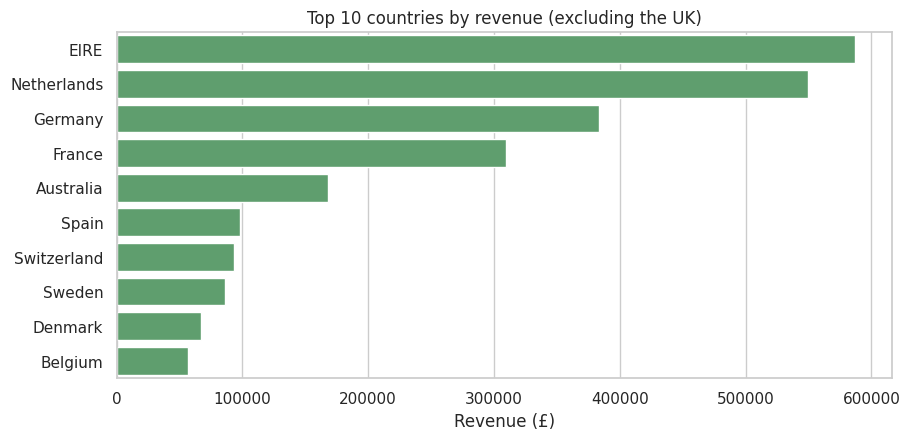

In [14]:
# revenue and customers per country
country = (df.groupby("Country")
             .agg(revenue=("Revenue", "sum"), customers=("CustomerID", "nunique"))   # two metrics in one go
             .sort_values("revenue", ascending=False))
country["revenue_share_%"] = (country["revenue"] / country["revenue"].sum() * 100).round(1)
print(country.head(8))

# the UK dominates so much that other bars would be invisible -> plot the top 10 EXCLUDING the UK
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=country.drop("United Kingdom").head(10).reset_index(), y="Country", x="revenue", color="#55A868", ax=ax)
ax.set_title("Top 10 countries by revenue (excluding the UK)")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("")
plt.savefig(IMAGES / "03_country_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** the UK provides ~84% of revenue. Outside the UK, EIRE, the Netherlands, Germany, France and Australia lead. Interesting detail: **EIRE has only 3 customers but ~3.4% of revenue** — a few very large wholesale accounts. For modelling I will use a simple **"is UK" flag** instead of 40+ country columns (fewer columns = simpler, less overfitting for a first model).

### 5.4 Best-selling products

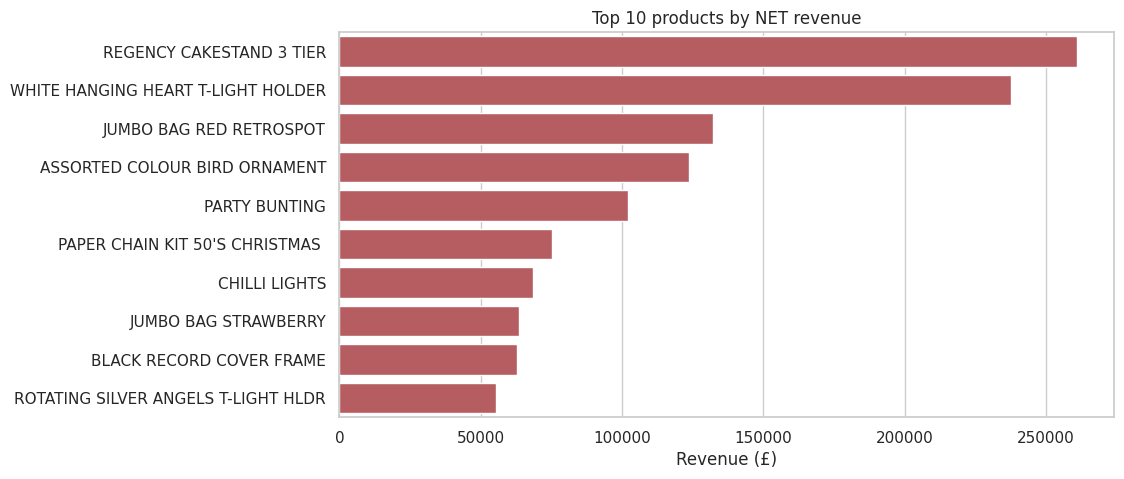

,Description,Revenue
0,REGENCY CAKESTAND 3 TIER,"261,110.95"
1,WHITE HANGING HEART T-LIGHT HOLDER,"237,678.61"
2,JUMBO BAG RED RETROSPOT,"132,180.02"
3,ASSORTED COLOUR BIRD ORNAMENT,"123,631.87"
4,PARTY BUNTING,"102,089.38"
5,PAPER CHAIN KIT 50'S CHRISTMAS,"75,388.48"
6,CHILLI LIGHTS,"68,453.50"
7,JUMBO BAG STRAWBERRY,"63,615.53"
8,BLACK RECORD COVER FRAME,"63,009.83"
9,ROTATING SILVER ANGELS T-LIGHT HLDR,"55,577.77"


In [15]:
# top 10 products by NET revenue (sales + returns). Grouping by Description is easier to read than StockCode.
# My first version used gross sales only and showed 'PAPER CRAFT, LITTLE BIRDIE' as #3 - but that was the
# £168k cancelled order! Including returns removes it from the list.
top_products = (all_lines.groupby("Description")["Revenue"].sum()
                  .sort_values(ascending=False).head(10).reset_index())

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_products, y="Description", x="Revenue", color="#C44E52", ax=ax)
ax.set_title("Top 10 products by NET revenue")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("")
plt.savefig(IMAGES / "04_top_products.png", dpi=150, bbox_inches="tight")
plt.show()
top_products

### 5.5 How often do customers buy? (the heart of retention)

count   5,852.00
mean        6.30
std        12.70
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       373.00
Name: Invoice, dtype: float64

Customers with only ONE order : 27.6%
Customers with 2+ orders (repeat): 72.4%


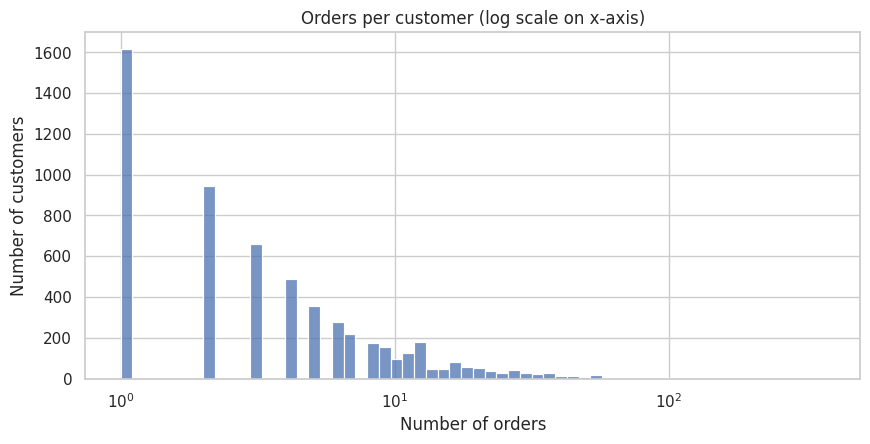

In [16]:
# number of distinct orders per customer
orders_per_customer = df.groupby("CustomerID")["Invoice"].nunique()

print(orders_per_customer.describe().round(1))                       # min, median, mean, max...
print(f"\nCustomers with only ONE order : {(orders_per_customer == 1).mean():.1%}")
print(f"Customers with 2+ orders (repeat): {(orders_per_customer > 1).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(orders_per_customer, bins=60, log_scale=(True, False), ax=ax)   # log x-axis because the data is very skewed
ax.set_title("Orders per customer (log scale on x-axis)")
ax.set_xlabel("Number of orders")
ax.set_ylabel("Number of customers")
plt.savefig(IMAGES / "05_orders_per_customer.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** most customers buy more than once (about 72%), but a long tail buys 20-100+ times (wholesale buyers). The distribution is **heavily right-skewed**, so for K-Means later I will apply a **log transform** — otherwise the few extreme customers would dominate the clusters.

### 5.6 Revenue concentration (Pareto / 80-20 check)

Customers with net revenue <= 0 (returned everything they bought): 41
Top 20% of customers generate 76.7% of revenue
Top  1% of customers generate 31.1% of revenue


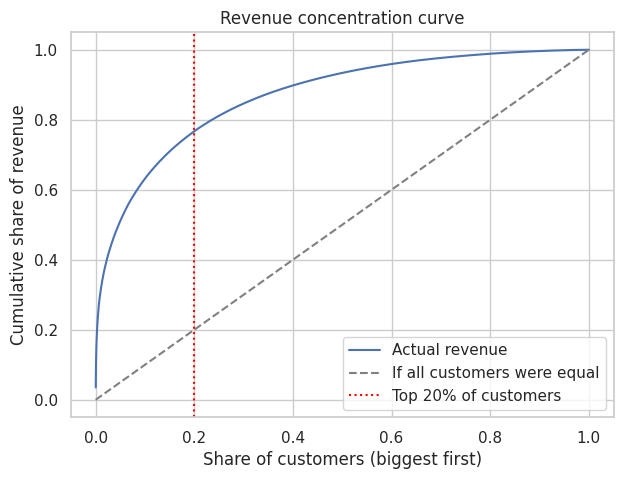

In [17]:
# NET revenue per customer (sales + returns), sorted from biggest to smallest
cust_rev = all_lines.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
print("Customers with net revenue <= 0 (returned everything they bought):", (cust_rev <= 0).sum())
cust_rev = cust_rev[cust_rev > 0]          # keep customers who kept some revenue, otherwise shares are meaningless

top20_n = int(len(cust_rev) * 0.20)                                  # how many customers are the top 20%
top20_share = cust_rev.head(top20_n).sum() / cust_rev.sum()          # their share of total revenue
top1_share = cust_rev.head(int(len(cust_rev) * 0.01)).sum() / cust_rev.sum()   # top 1%
print(f"Top 20% of customers generate {top20_share:.1%} of revenue")
print(f"Top  1% of customers generate {top1_share:.1%} of revenue")

# cumulative curve: x = share of customers, y = share of revenue
cum_share = cust_rev.cumsum() / cust_rev.sum()
x = np.arange(1, len(cum_share) + 1) / len(cum_share)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, cum_share.values, label="Actual revenue")
ax.plot([0, 1], [0, 1], "--", color="grey", label="If all customers were equal")   # reference line
ax.axvline(0.2, color="red", linestyle=":", label="Top 20% of customers")
ax.set_title("Revenue concentration curve")
ax.set_xlabel("Share of customers (biggest first)")
ax.set_ylabel("Cumulative share of revenue")
ax.legend()
plt.savefig(IMAGES / "06_pareto_curve.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** the top 20% of customers produce ~77% of net revenue and the top 1% alone ~31% (a very strong Pareto pattern). **Business meaning:** losing a few top customers hurts far more than losing many small ones, so the retention plan should be **value-weighted** — I will do exactly that in notebook 05.

### 5.7 When do customers shop? (weekday × hour)

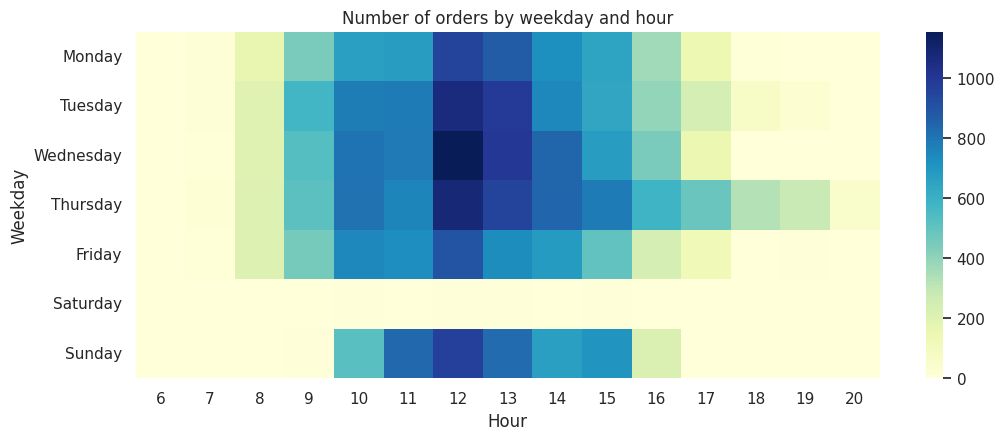

Orders on Saturday: 30


In [18]:
# create two helper columns from the timestamp
df["Weekday"] = df["InvoiceDate"].dt.day_name()          # Monday, Tuesday...
df["Hour"] = df["InvoiceDate"].dt.hour                   # 0-23

# count unique orders for each weekday-hour combination
heat = (df.drop_duplicates("Invoice")                    # one row per order so I count orders, not lines
          .groupby(["Weekday", "Hour"]).size()
          .unstack(fill_value=0))                        # reshape: rows = weekday, columns = hour
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = heat.reindex(order)                               # put weekdays in natural order

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(heat, cmap="YlGnBu", ax=ax)
ax.set_title("Number of orders by weekday and hour")
plt.savefig(IMAGES / "07_weekday_hour_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Orders on Saturday:", int(heat.loc["Saturday"].sum()))

**Insight:** almost no orders on Saturdays (only 30 in two years), Thursday is the busiest day (~7,700 orders) and orders peak around midday (12:00-13:00) — a working-hours pattern typical of a **B2B / wholesale** customer base rather than consumers shopping at weekends.

## Step 6 · Save the cleaned data
**What:** write the clean tables to `data/processed/`. **Why:** the SQL part loads `transactions_clean.csv`; the ML notebooks use `returns_clean.csv`. Saving once means every later step starts from the *same* trusted data.

In [19]:
# choose the columns (and order) that will go into MySQL
sales_cols = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "CustomerID", "Country", "Revenue"]
returns_cols = sales_cols                                  # same structure, but Revenue is negative

df[sales_cols].to_csv(PROCESSED / "transactions_clean.csv", index=False)        # clean sales
returns[returns_cols].to_csv(PROCESSED / "returns_clean.csv", index=False)      # cancellations
log_df.to_csv(PROCESSED / "cleaning_log.csv", index=False)                      # the audit trail

print("Saved:", [p.name for p in PROCESSED.iterdir()])
print("Clean sales rows:", len(df), "| returns rows:", len(returns))

Saved: ['cleaning_log.csv', 'customer_rfm.csv', 'churn_features.csv', 'transactions_clean.csv', 'returns_clean.csv', 'customer_segments.csv']
Clean sales rows: 776579 | returns rows: 17586


## Summary & what I learned in this notebook
- ✅ Cleaned 1.07 M raw rows to ~776 k reliable sales rows, with a logged, reproducible process.
- ✅ Found and handled a hidden problem: **4 of the 5 largest orders were cancelled** → money is measured *net of returns* (returns = ~4% of gross sales value).
- ✅ Learned a floating-point lesson: always `.round(2)` money columns, otherwise tiny residues (1e-13) break "is this customer's net revenue > 0?" checks.
- ✅ Business insights: strong Sept–Nov seasonality, UK = ~84% of revenue, top 20% of customers = ~77% of net revenue, B2B shopping pattern.
- ✅ Decisions for later: log-transform skewed features, add an `is_UK` flag, use value-weighted retention.

**Next → `sql/` folder:** load the clean data into MySQL and answer business questions with SQL, then build RFM segments.